# Noisy CIFAR-100 — raport


Baseline-ul a progresat de la **15,82% la 37,04% validare noisy** prin SGD, cosine scheduling
și crop/flip. Pentru 01–04 am folosit splitul 45k/5k și câte 160 de epoci finale.

| Notebook Kaggle | Tratarea zgomotului | Scor Kaggle |
|---|---|---:|
| [01 — KNN](https://www.kaggle.com/code/mik33y/01-before-knn) | Înainte | 0,5934 |
| [02 — Clustering](https://www.kaggle.com/code/mik33y/02-before-clustering) | Înainte | 0,5812 |
| [03 — Small loss](https://www.kaggle.com/code/mik33y/03-during-small-loss) | În timpul | 0,5942 |
| [04 — Confidence](https://www.kaggle.com/code/mik33y/04-during-confidence) | În timpul | 0,6062 |
| [05 — Best](https://www.kaggle.com/code/mik33y/05-full-train-2-with-precomparison?scriptVersionId=367007280) | În timpul + ensemble | **0,7065** |


### Evoluția baseline-ului

| Etapă | Best validare noisy |
|---|---:|
| Baseline inițial | 15,82% |
| SGD cu momentum și cosine scheduling | 29,20% |
| Crop și horizontal flip | 37,04% |

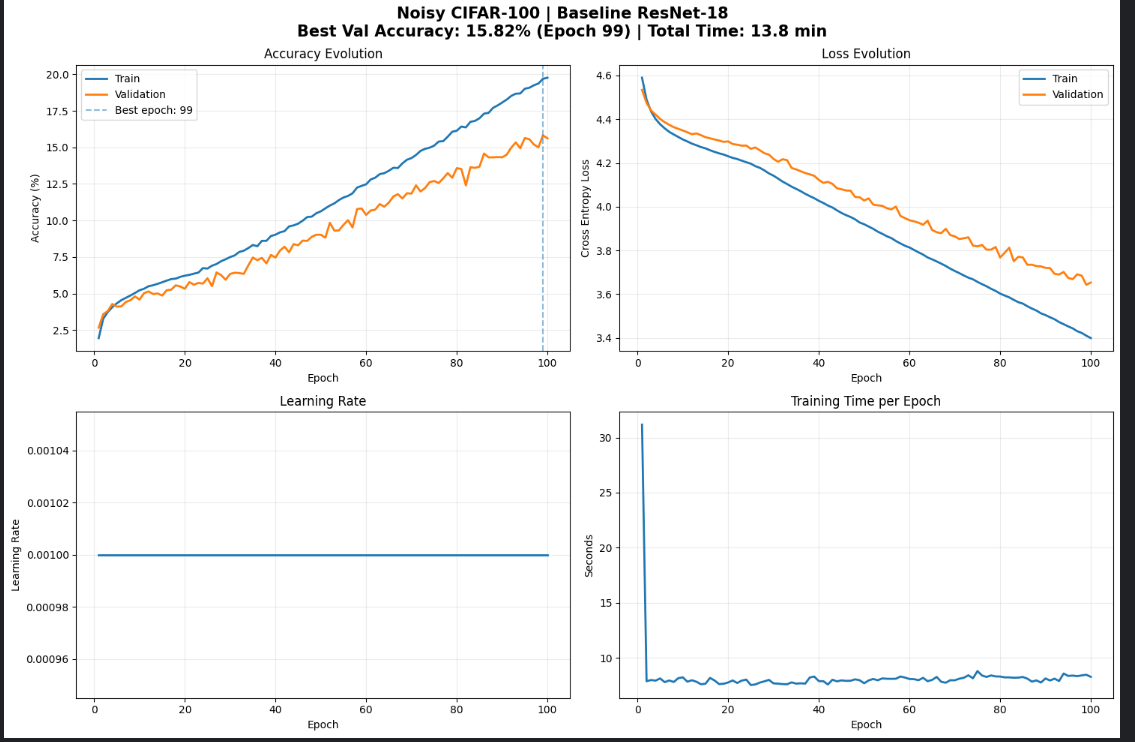

**Punct de plecare:** LR constant 0,001, progres lent, best la epoca 99.

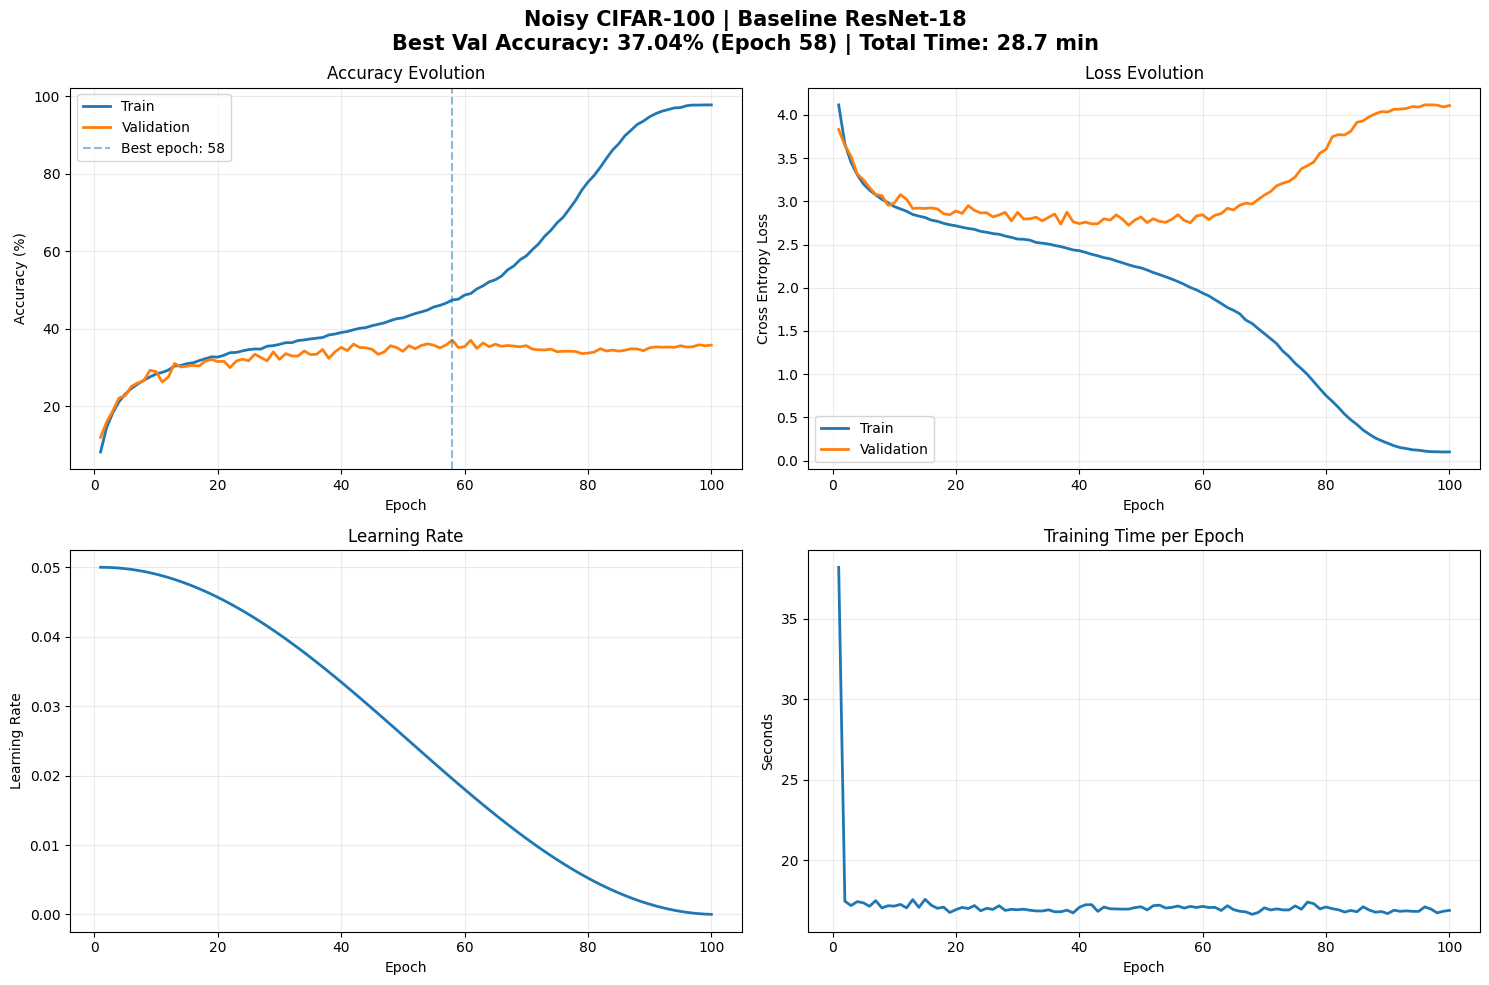

**După optimizare și augmentare:** best 37,04% la epoca 58, cu **21,22 puncte** peste prima variantă.
Train accuracy se apropie de 100%, dar validarea stagnează: mai multe epoci nu rezolvă singure
problema etichetelor noisy. 


## 01 — Corectare prin KNN, înainte de antrenare

Un ResNet18 auxiliar, antrenat de la zero 30 de epoci, produce reprezentările imaginilor.
KNN propune etichete prin consens de minimum 90% între 50 de vecini, excluzând imaginea însăși.

Am modificat **283 de etichete**, apoi am antrenat un clasificator nou cu etichetele fixe,
fără alte corecții sau filtrări în timpul antrenării finale.
Best validare noisy: **49,00%, epoca 43**. Kaggle: **0,5934**. Durată: **aproximativ 1 h 19 min**.


## 02 — Corectare prin clustering, înainte de antrenare

MiniBatchKMeans grupează reprezentările modelului auxiliar; consensul din microclustere
propune corecțiile. Clasificatorul final pornește de la zero, cu etichetele și imaginile fixe.

Au fost modificate **897 de etichete**, fără imagini eliminate.
Best validare noisy: **48,24%, epoca 39**. Kaggle: **0,5812**. Durată: **aproximativ 1 h 32 min**.
Mai multe corecții nu au însemnat un rezultat mai bun decât KNN.


## 03 — Small loss, în timpul antrenării

Am pornit de la etichetele noisy originale, fără prefiltrare. După warmup, am urmărit
istoricul lossului și am comparat exemplele în interiorul fiecărei clase. Exemplele
suspecte primesc o pondere mică, **0,05**, astfel încât contribuția lor la gradient scade.

Ponderarea începe la **epoca 26** și ajunge la **8.960 de exemple**. Nu am eliminat imagini
și nu am rescris etichete. Best validare noisy: **48,20%, epoca 63**.
Kaggle: **0,5942**. Durată: **aproximativ 1 h 36 min**.

La final, train accuracy ajunge la **89,34%**, dar validarea scade la **45,96%**.
Am folosit checkpointul ales pe validare, nu ultima epocă.


## 04 — Confidence temporală, în timpul antrenării

Am urmărit predicțiile pe mai multe epoci. Dezacordurile reduc ponderea exemplelor;
o alternativă sigură și stabilă permite corectarea graduală prin ținte soft.
Pentru exemplele incerte am folosit smoothing. Nu am corectare înainte de antrenare.

Intervențiile încep la **epoca 26**; au fost maximum **1.136 de corecții soft**.
Best validare noisy: **49,70%, epoca 52**. Kaggle: **0,6062**.
Durată: **aproximativ 1 h 41 min**.

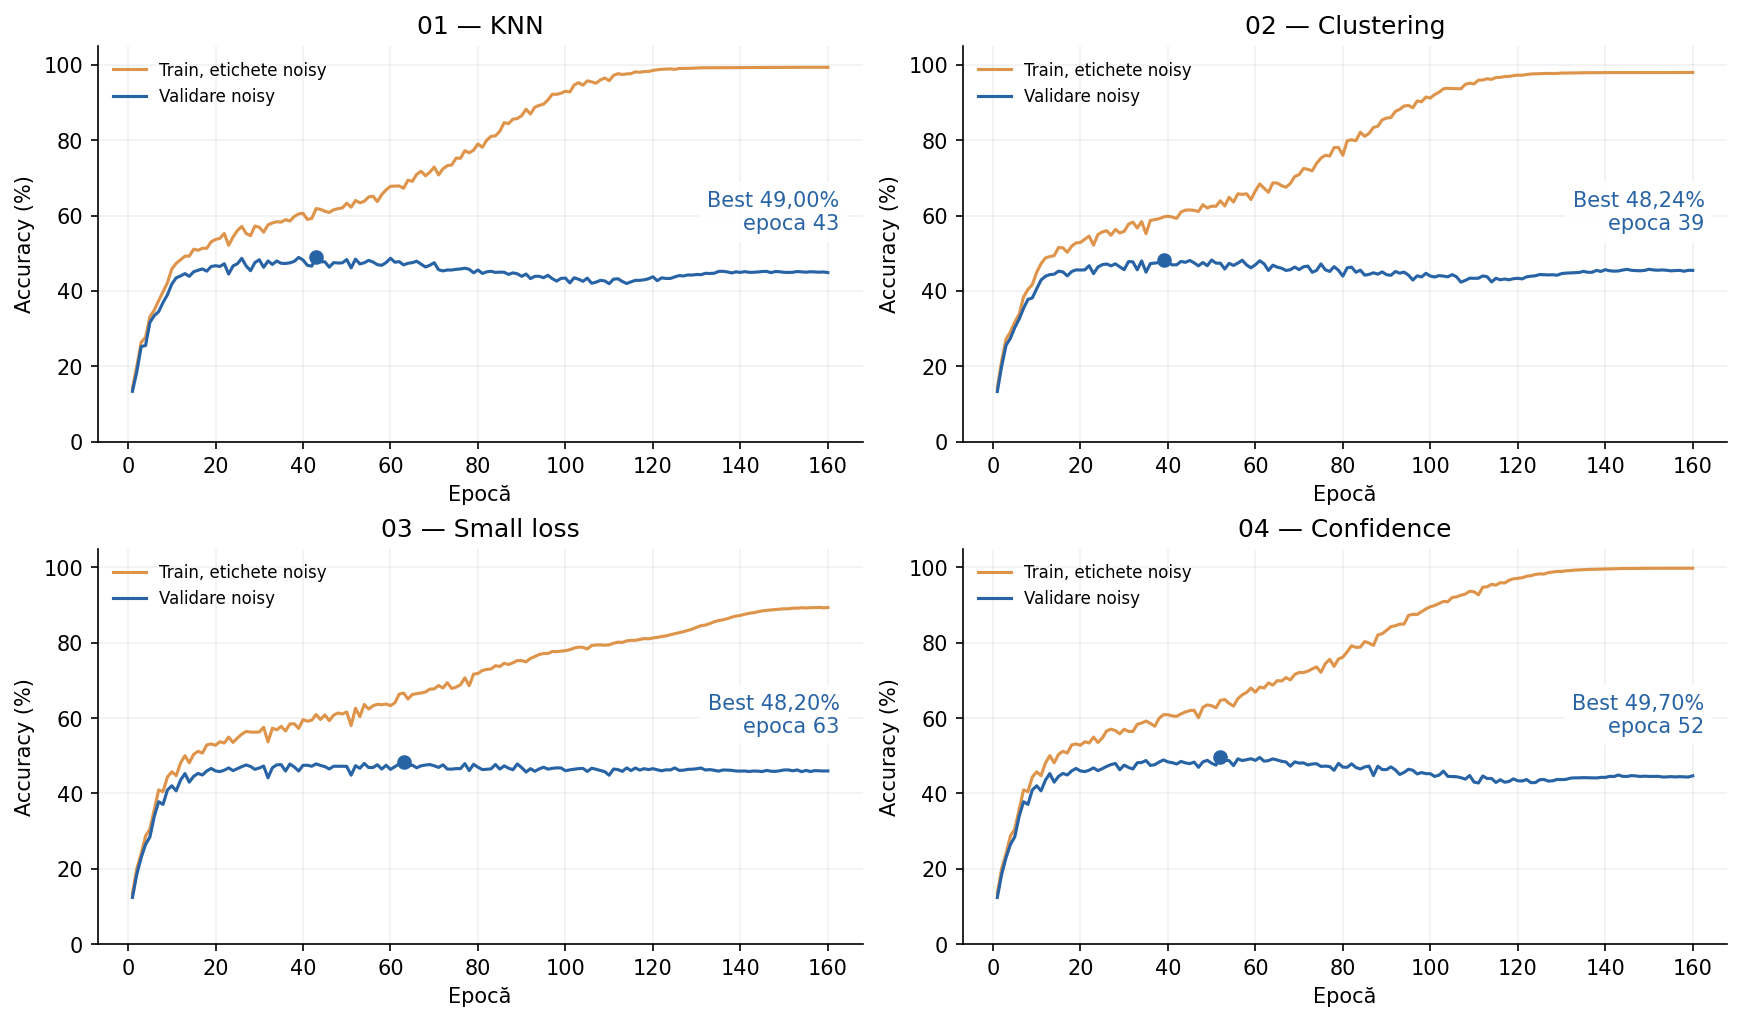

**Concluzie:** 04 obține cel mai bun scor dintre metodele de bază; 03 este apropiat de 01.
Curbele arată că train accuracy mare nu asigură generalizare. Numerele de corecții și ponderări
reprezintă deciziile algoritmilor, nu etichete greșite verificate.



**Intervenții în timp:** 03 menține o pondere redusă pentru 8.960 de exemple; 04 reevaluează ponderile
și corecțiile, care scad spre final. Această scădere nu demonstrează că toate etichetele au devenit corecte.


## 05 — Modelul best și implementarea

Am combinat principiile de **consens, loss, ponderare și ținte soft** într-o adaptare DivideMix.
Folosesc două PreActResNet18 independente; KNN și clusteringul semantic din 01–02 nu sunt
aplicate direct în această rețetă.

1. **Warmup:** 30 de epoci cu etichetele furnizate, pentru reprezentări inițiale.
2. **Selecție reciprocă:** fiecare rețea ajustează un GMM cu două componente pe lossurile
   imaginilor train. Rețeaua A folosește selecția lui B și invers.
3. **Corectare soft:** încrederea estimată combină eticheta furnizată cu predicția modelului.
   Imaginile suspecte rămân utilizate ca exemple fără etichetă sigură.
4. **MixMatch și MixUp:** predicțiile celor două rețele și vederile augmentate generează
   pseudoetichete; imaginile și țintele sunt amestecate pentru regularizare.
5. **Final full train:** după alegerea rețetei pe holdout, antrenez două rețele noi pe toate
   cele **50.000 de imagini**. Runul best a terminat **300 de epoci**.
6. **Inferență:** EMA mediază ponderile, BN este recalibrat numai pe train, iar predicțiile
   sunt mediate între rețele și între imaginea originală și flip.

| Parametru al rețetei best | Valoare |
|---|---|
| Optimizare | SGD, LR 0,02 → 0,002 după epoca 150; momentum 0,9; weight decay 0,0005 |
| Batch / MixUp / temperatură | 64 / α = 4 / T = 0,5 |
| Prag GMM / coeficient nesupervizat | 0,5 / 25 |
| EMA | 0,999, separat pentru fiecare rețea |

Modelul full-data nu mai are un holdout independent: fostul holdout intră în antrenare.

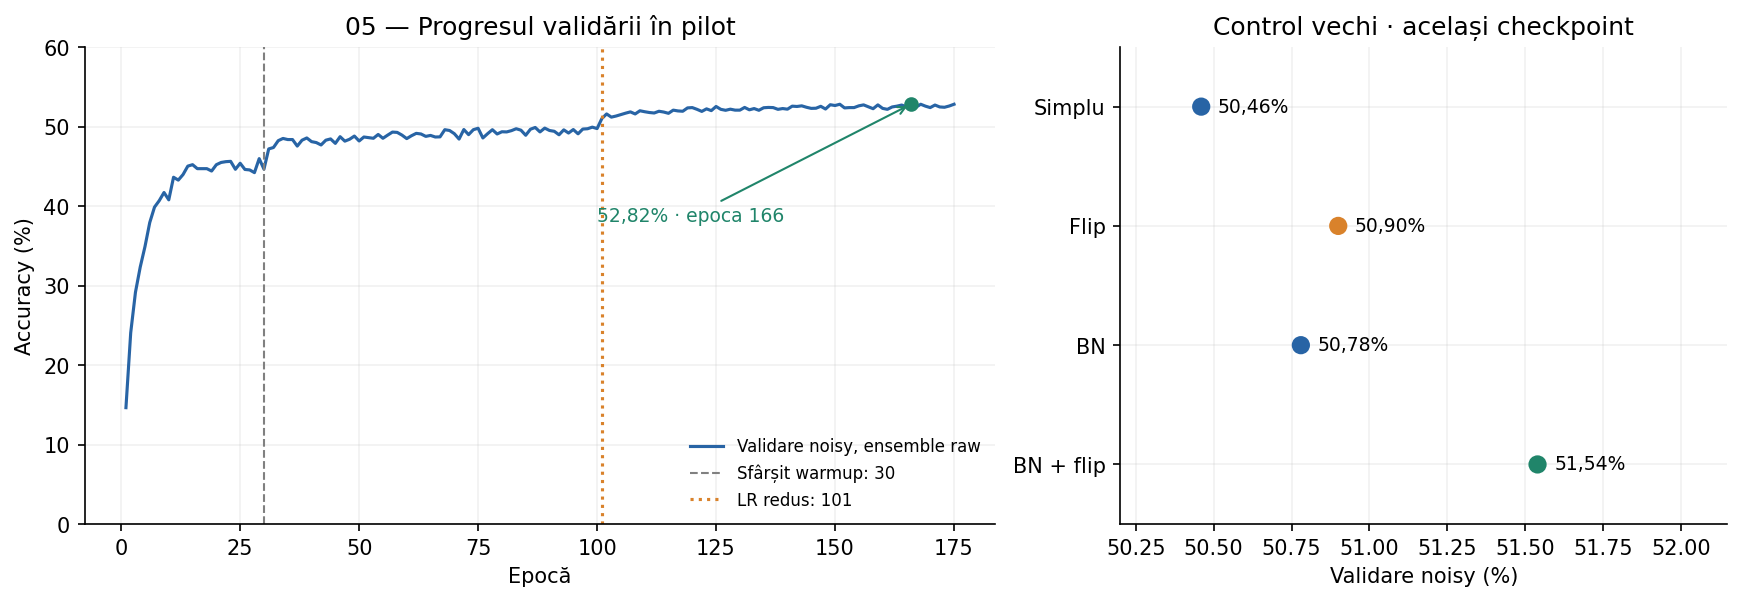

**Progres măsurat:** pilotul urcă de la 44,64% la epoca 30 la **52,82% la epoca 166**;
reducerea LR începe la epoca 101. Curba este validarea raw a pilotului, nu a finalului full-data.
Separat, pe checkpointul controlului vechi, BN + flip aduce **50,46% → 51,54%**, fără reantrenare.


### 05 — Experimente și concluzii

| Variantă | Rezultat | Concluzie |
|---|---:|---|
| Corectare temporală + MixUp | 0,6508 Kaggle | Punct de comparație |
| RandAugment global | 0,6472 Kaggle | Nu a îmbunătățit controlul |
| SOP+ adaptat | 49,26% validare noisy; netrimis | Direcție abandonată |
| ResNet34 + MixUp | 0,6506 Kaggle | Profunzimea singură nu a ajutat |
| Full train, 300 epoci | 0,6968 Kaggle | Progres față de variantele inițiale |
| Full train + EMA | **0,7065 Kaggle** | **Best confirmat** |
| Ultimul 05, versiunea 13 Nov | 0,7001 Kaggle | Sub best cu **0,64 puncte procentuale** |

**Optuna** a căutat pragul GMM și coeficientul nesupervizat. Mediile ultimelor cinci epoci:
**0,5 / 25 → 50,916%**, respectiv
**0,6 / 10 → 50,812%**, după 80 de epoci.
Al treilea trial s-a oprit la 75/80 din cauza timpului. Am păstrat **0,5 / 25**.

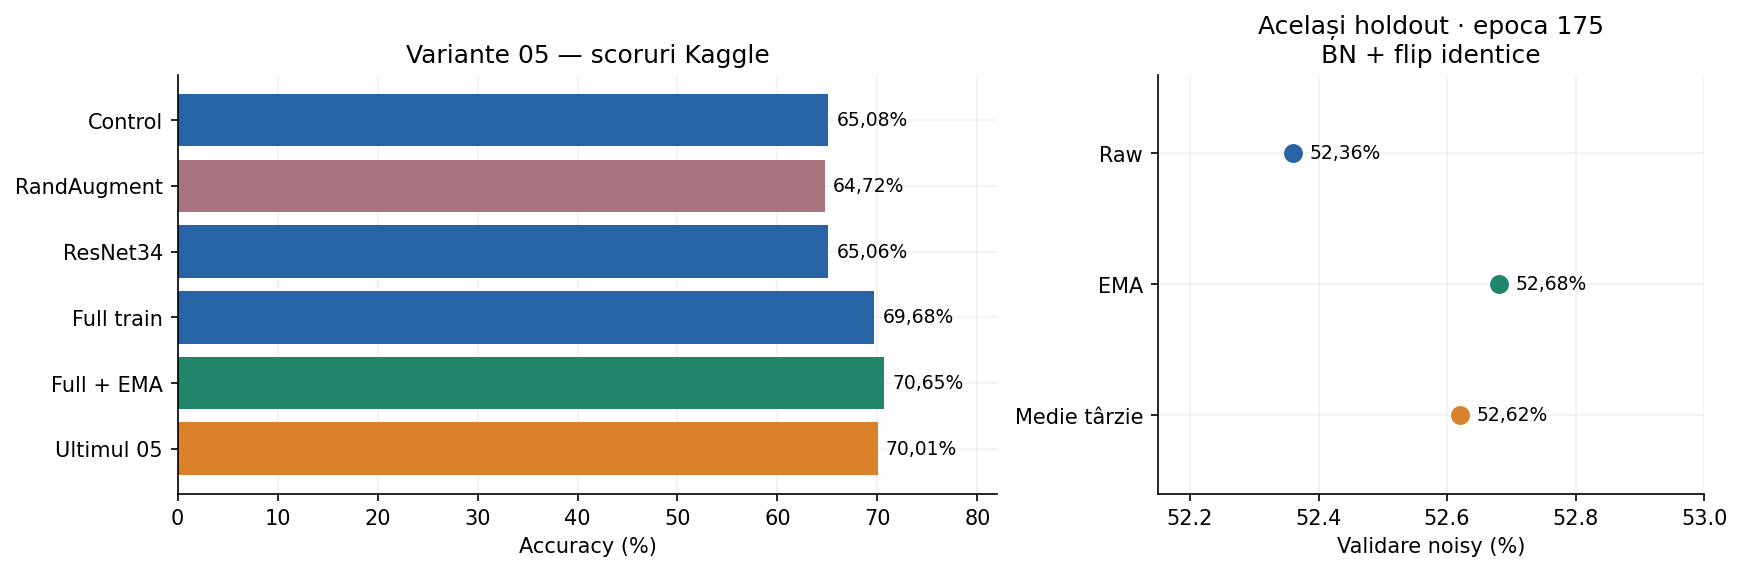

Comparația pe același holdout susține alegerea EMA: **52,68% față de 52,36% raw**.
Într-un alt test, AugDesc a terminat numai 53/60 de epoci, astfel că efectul său a rămas neconcludent.

**Ultima extensie implementată:** selecție pe clase, recuperare prin confidence ≥ 0,95,
consens stabil trei epoci și istoric al predicțiilor care influențează moderat țintele soft.
Cel mult 90% dintre imagini sunt considerate sigure simultan. Codul compară controlul cu
extensia pe holdout, apoi antrenează de la zero rețeta aleasă.

Ultimul submission, **05_last_try_13Nov V1**, nu a depășit best-ul **0,7065**.
Fără logul său nu atribuim scăderea unei componente sau unei rețete selectate.

Implementarea best: [05 — full train cu precomparație](https://www.kaggle.com/code/mik33y/05-full-train-2-with-precomparison?scriptVersionId=367007280).
